In [13]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy

In [14]:
data_raw = pd.read_csv('evidence_fib_reran.txt', sep='\t', low_memory=False)

data_fibrin = data_raw[data_raw['Gene names'].isin(['FGA', 'FGB', 'FGG'])]
data_imac = data_raw[data_raw['Fraction'] == 1]
data_ft = data_raw[data_raw['Fraction'] == 2]

In [15]:
def process_data(data):

     samples = list(set(data['Experiment']))
     conditions = list(set([x.rstrip('_0123') for x in samples]))

     total = []
     modified = []
     for sample in samples:
          total.append(int(data['Experiment'].value_counts().get(sample, 0)))
          modified.append(int(data[data['Modifications'] == 'KS22027DI']['Experiment'].value_counts().get(sample, 0)))

     peptide_counts = pd.DataFrame({'sample' : samples,
                                    'total' : total,
                                    'modified' : modified})

     peptide_counts.sort_values(by=['sample'], inplace=True)

     total_mean = []
     total_std = []
     modified_mean = []
     modified_std = []
     index = 0
     for condition in conditions:
          total_mean.append(np.mean(peptide_counts['total'][index : index + 3]))
          total_std.append(np.std(peptide_counts['total'][index : index + 3]))
          modified_mean.append(np.mean(peptide_counts['modified'][index : index + 3]))
          modified_std.append(np.std(peptide_counts['modified'][index : index + 3]))
          index += 3

          conditions = np.sort(list(conditions))

     mean_data = pd.DataFrame({'condition' : conditions,
                               'total' : total_mean,
                               'total_std' : total_std,
                               'modified' : modified_mean,
                               'modified_std' : modified_std}).round(4)
     
     mean_data['unmodified'] = mean_data['total'] - mean_data['modified']

     return mean_data, peptide_counts

In [16]:
all_mean, all = process_data(data_raw)
all_mean = all.reindex({1 : 0, 2 : 1, 5 : 2, 4 : 3, 3 : 4, 0 : 5, 6 : 6, 7 : 7}).reset_index().drop(columns='index')
all_mean

,sample,total,modified
0,t30_cont_01,2100,135
1,t30_cont_03,2211,28
2,t0_CONT_02,1531,21
3,tON_CONT_03,2239,22
4,tON_PAD4_01,1949,427
5,T120_PAD4_03,1809,461
6,t120_CONT_01,2524,174
7,t120_CONT_03,2292,46


In [17]:
imac_mean, imac = process_data(data_imac)
imac_mean = imac_mean.reindex({1 : 0, 2 : 1, 5 : 2, 4 : 3, 3 : 4, 0 : 5, 6 : 6, 7 : 7}).reset_index().drop(columns='index')
imac_mean

,condition,total,total_std,modified,modified_std,unmodified
0,t0_CONT,277.3333,22.1259,31.6667,8.5765,245.6666
1,t0_PAD4,297.6667,31.6789,27.3333,5.5578,270.3334
2,t30_cont,317.6667,47.6818,71.6667,45.8427,246.0000
3,t30_PAD4,1021.3333,100.6656,698.3333,99.8744,323.0000
4,t120_CONT,366.0000,35.8608,109.0000,52.6688,257.0000
5,T120_PAD4,759.0000,34.5640,442.3333,14.3836,316.6667
6,tON_CONT,292.0000,53.7649,69.3333,56.0079,222.6667
7,tON_PAD4,966.3333,14.1970,443.6667,27.1334,522.6666


In [18]:
ft_mean, ft = process_data(data_ft)
ft_mean = ft_mean.reindex({1 : 0, 2 : 1, 5 : 2, 4 : 3, 3 : 4, 0 : 5, 6 : 6, 7 : 7}).reset_index().drop(columns='index')
ft_mean

,condition,total,total_std,modified,modified_std,unmodified
0,t0_CONT,1411.3333,120.6381,0.0000,0.0000,1411.3333
1,t0_PAD4,1570.0000,114.7374,0.0000,0.0000,1570.0000
2,t30_cont,1788.6667,104.8947,0.0000,0.0000,1788.6667
3,t30_PAD4,1287.3333,121.6945,0.0000,0.0000,1287.3333
4,t120_CONT,1898.3333,216.3798,0.3333,0.4714,1898.0000
5,T120_PAD4,1230.3333,150.9003,0.6667,0.9428,1229.6666
6,tON_CONT,1618.3333,272.2160,1.3333,1.2472,1617.0000
7,tON_PAD4,996.6667,56.3402,1.0000,0.8165,995.6667


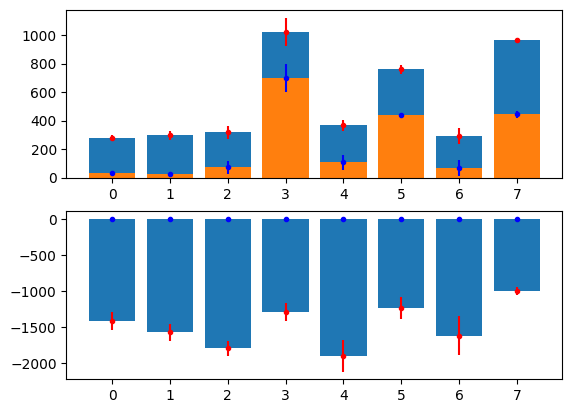

In [19]:
fig, axs = plt.subplots(2, 1)

x_val = [0, 1, 2, 3, 4, 5, 6, 7]
axs[0].bar(x_val, imac_mean['total'])
axs[0].bar(x_val, imac_mean['modified'])
axs[1].bar(x_val, - ft_mean['total'])
axs[1].bar(x_val, - ft_mean['modified'])
axs[0].errorbar(x_val, imac_mean['total'], yerr = imac_mean['total_std'], fmt='r.')
axs[0].errorbar(x_val, imac_mean['modified'], yerr = imac_mean['modified_std'], fmt='b.')
axs[1].errorbar(x_val, - ft_mean['total'], yerr = ft_mean['total_std'], fmt='r.')
axs[1].errorbar(x_val, - ft_mean['modified'], yerr = ft_mean['modified_std'], fmt='b.')

fig.savefig('C:/Users/kathe/OneDrive - Sanquin/_Project data/Code/bars_peptides.svg')


In [20]:
samples = list(x.rstrip('_0123').lower() for x in imac['sample'])
conditions = []
[conditions.append(x) for x in samples if x not in conditions]

index = 0
imac_groups = pd.DataFrame()
for condition in conditions:
    imac_groups[condition] = imac['modified'][index : index + 3].to_numpy()
    index += 3

In [21]:
result = scipy.stats.tukey_hsd(imac_groups['t0_pad4'],
                               imac_groups['t30_pad4'],
                               imac_groups['t120_pad4'],
                               imac_groups['ton_pad4'],
                               )
print(result)

Pairwise Group Comparisons (95.0% Confidence Interval)
Comparison  Statistic  p-value  Lower CI  Upper CI
 (0 - 1)   -671.000     0.000  -838.542  -503.458
 (0 - 2)   -415.000     0.000  -582.542  -247.458
 (0 - 3)   -416.333     0.000  -583.875  -248.791
 (1 - 0)    671.000     0.000   503.458   838.542
 (1 - 2)    256.000     0.005    88.458   423.542
 (1 - 3)    254.667     0.005    87.125   422.209
 (2 - 0)    415.000     0.000   247.458   582.542
 (2 - 1)   -256.000     0.005  -423.542   -88.458
 (2 - 3)     -1.333     1.000  -168.875   166.209
 (3 - 0)    416.333     0.000   248.791   583.875
 (3 - 1)   -254.667     0.005  -422.209   -87.125
 (3 - 2)      1.333     1.000  -166.209   168.875



In [22]:
result.pvalue

array([[1.00000000e+00, 6.05972800e-06, 2.13793637e-04, 2.08963542e-04],
       [6.05972800e-06, 1.00000000e+00, 5.27193206e-03, 5.44038357e-03],
       [2.13793637e-04, 5.27193206e-03, 1.00000000e+00, 9.99993519e-01],
       [2.08963542e-04, 5.44038357e-03, 9.99993519e-01, 1.00000000e+00]])

In [23]:
result = scipy.stats.tukey_hsd(imac_groups['t0_cont'],      # 0
                               imac_groups['t30_cont'],     # 1
                               imac_groups['t120_cont'],    # 2
                               imac_groups['ton_cont'],     # 3
                               imac_groups['t0_pad4'],      # 4
                               imac_groups['t30_pad4'],     # 5
                               imac_groups['t120_pad4'],    # 6
                               imac_groups['ton_pad4'],     # 7
                               )
print(result)

Pairwise Group Comparisons (95.0% Confidence Interval)
Comparison  Statistic  p-value  Lower CI  Upper CI
 (0 - 1)    -40.000     0.989  -208.879   128.879
 (0 - 2)    -77.333     0.752  -246.213    91.546
 (0 - 3)    -37.667     0.992  -206.546   131.213
 (0 - 4)      4.333     1.000  -164.546   173.213
 (0 - 5)   -666.667     0.000  -835.546  -497.787
 (0 - 6)   -410.667     0.000  -579.546  -241.787
 (0 - 7)   -412.000     0.000  -580.879  -243.121
 (1 - 0)     40.000     0.989  -128.879   208.879
 (1 - 2)    -37.333     0.993  -206.213   131.546
 (1 - 3)      2.333     1.000  -166.546   171.213
 (1 - 4)     44.333     0.981  -124.546   213.213
 (1 - 5)   -626.667     0.000  -795.546  -457.787
 (1 - 6)   -370.667     0.000  -539.546  -201.787
 (1 - 7)   -372.000     0.000  -540.879  -203.121
 (2 - 0)     77.333     0.752   -91.546   246.213
 (2 - 1)     37.333     0.993  -131.546   206.213
 (2 - 3)     39.667     0.990  -129.213   208.546
 (2 - 4)     81.667     0.702   -87.213   25

In [24]:
result.pvalue

array([[1.00000000e+00, 9.89213117e-01, 7.52103002e-01, 9.92395967e-01,
        9.99999996e-01, 7.19095750e-09, 6.38441186e-06, 6.11953672e-06],
       [9.89213117e-01, 1.00000000e+00, 9.92783751e-01, 1.00000000e+00,
        9.80744405e-01, 1.78330601e-08, 2.37113418e-05, 2.26672547e-05],
       [7.52103002e-01, 9.92783751e-01, 1.00000000e+00, 9.89720931e-01,
        7.02378766e-01, 4.35069367e-08, 8.68150440e-05, 8.27811223e-05],
       [9.92395967e-01, 1.00000000e+00, 9.89720931e-01, 1.00000000e+00,
        9.85755925e-01, 1.68908056e-08, 2.19157731e-05, 2.09540654e-05],
       [9.99999996e-01, 9.80744405e-01, 7.02378766e-01, 9.85755925e-01,
        1.00000000e+00, 6.53515098e-09, 5.56480715e-06, 5.33542775e-06],
       [7.19095750e-09, 1.78330601e-08, 4.35069367e-08, 1.68908056e-08,
        6.53515098e-09, 1.00000000e+00, 1.58673448e-03, 1.67194796e-03],
       [6.38441186e-06, 2.37113418e-05, 8.68150440e-05, 2.19157731e-05,
        5.56480715e-06, 1.58673448e-03, 1.00000000e+00, 1.